In [1]:
from Outsu_funs import *

# Import data

## Image downloading

In [5]:
name = "0333"

In [ ]:
#!cp /mnt/c/users/helen/Desktop/training_data/{name}.tif ./training_data_Outsu/{name}.tif

Image shape: (512, 512)
Data type: uint16


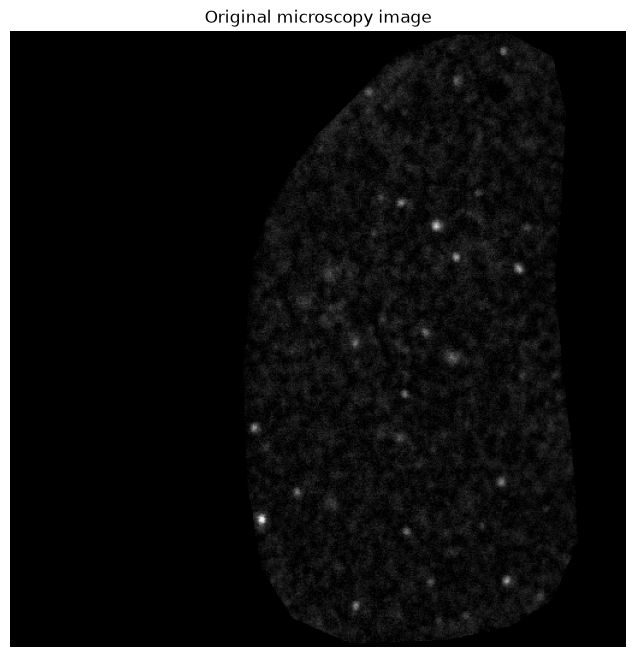

In [7]:
image_path = "training_data_Outsu/"+ name + ".tif"

image = io.imread(image_path)

print("Image shape:", image.shape)
print("Data type:", image.dtype)

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(image, cmap="gray")
ax.set_title("Original microscopy image")
ax.axis("off")

plt.show()

# Thresholding

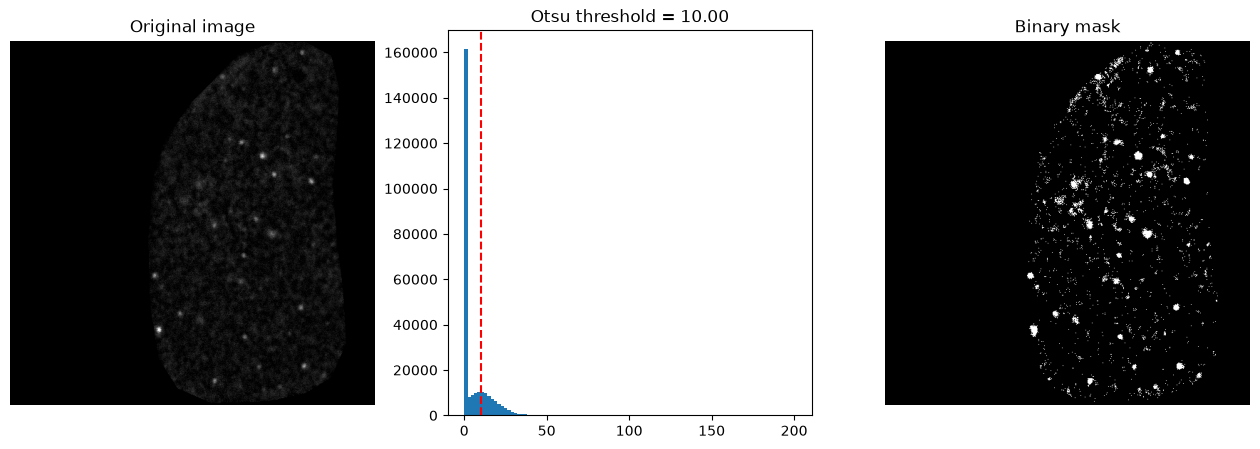

In [8]:
threshold = filters.threshold_otsu(image)
threshold_factor = 3

binary_mask = image > threshold * threshold_factor

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original image")

axes[1].hist(image.ravel(), bins=100)
axes[1].axvline(threshold, color="red", linestyle="--")
axes[1].set_title(f"Otsu threshold = {threshold:.2f}")

axes[2].imshow(binary_mask, cmap="gray")
axes[2].set_title("Binary mask")

for ax in [axes[0], axes[2]]:
    ax.axis("off")

# Cleaning

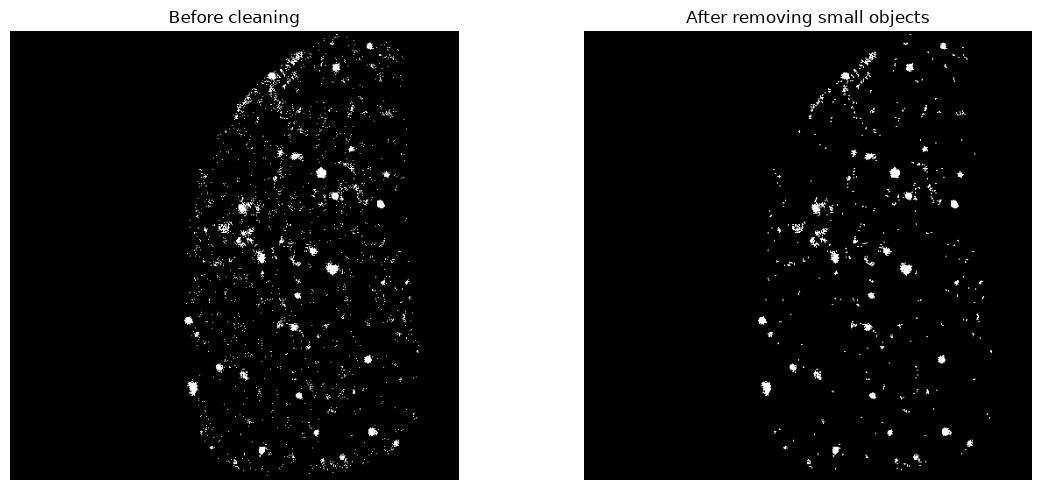

In [9]:
min_area = 2  # pixels

clean_mask = morphology.remove_small_objects(
    binary_mask,
    min_size=min_area
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(binary_mask, cmap="gray")
axes[0].set_title("Before cleaning")

axes[1].imshow(clean_mask, cmap="gray")
axes[1].set_title("After removing small objects")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Watersheding

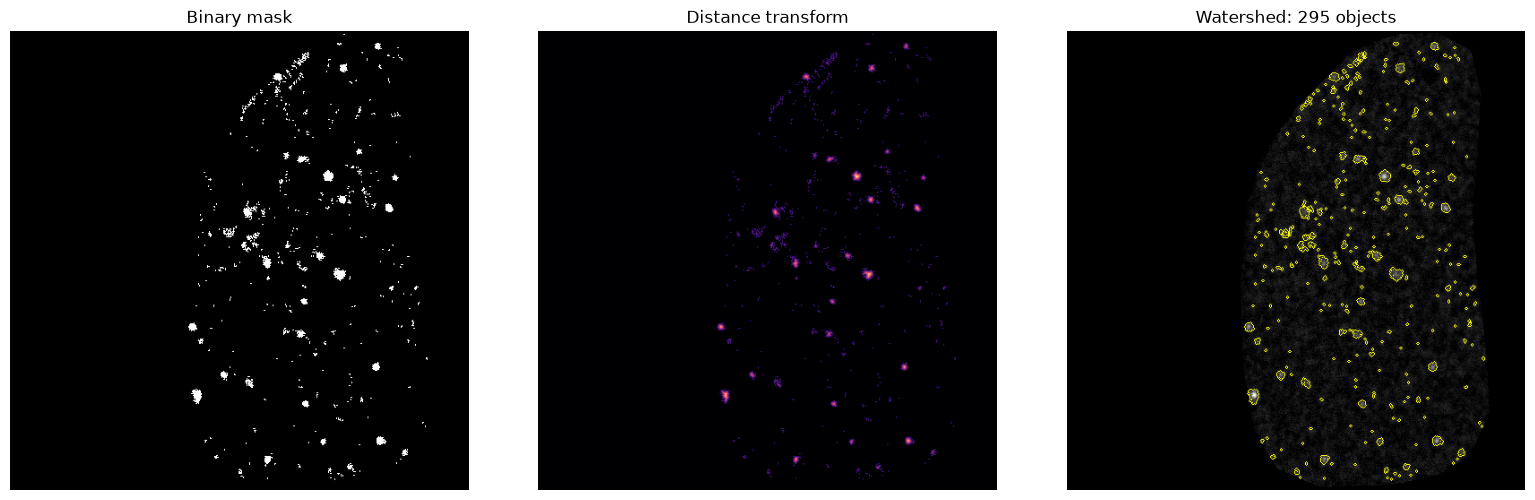

In [10]:
image_float = image.astype(np.float32)

distance = ndi.distance_transform_edt(clean_mask)

# Detect candidate centers
coordinates = peak_local_max(
    distance,
    min_distance=5,
    labels=clean_mask
)

markers = np.zeros_like(clean_mask, dtype=np.int32)

for i, (y, x) in enumerate(coordinates, start=1):
    markers[y, x] = i

labels = segmentation.watershed(
    -distance,
    markers,
    mask=clean_mask
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(clean_mask, cmap="gray")
axes[0].set_title("Binary mask")

axes[1].imshow(distance, cmap="magma")
axes[1].set_title("Distance transform")

axes[2].imshow(
    segmentation.mark_boundaries(
        image_float / (image_float.max() + 1e-8),
        labels
    )
)
axes[2].set_title(f"Watershed: {labels.max()} objects")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Features analysis

In [11]:
properties = measure.regionprops_table(
    labels,
    intensity_image=image_float,
    properties=[
        "label",
        "area",
        "centroid",
        "equivalent_diameter_area",
        "eccentricity",
        "solidity",
        "perimeter",
        "mean_intensity",
        "max_intensity",
        "min_intensity"
    ]
)

df = pd.DataFrame(properties)

# Circularity: 1 means approximately circular
df["circularity"] = (
    4 * np.pi * df["area"]
    / (df["perimeter"] ** 2 + 1e-8)
)

df["image_id"] = Path(image_path).name

#display(df.head())

print("Total detected objects:", len(df))

Total detected objects: 295


In [12]:
# Save the DataFrame to a CSV file
df.to_csv("training_data_Outsu/"+ name + ".csv", index=False)

### Descriptive statistics of data

In [ ]:
#df.describe()

## Feature subset and visualization

In [ ]:
#subset = df[(df['area'] > 2)]

#plot_image(
 #   image,
 #   clean_mask,
 #   labels,
 #   df,
 #   mode="image"
#)

In [13]:
#inxs = df[df["area"] > 2.5].index.tolist()

inxs = df.index.tolist()

print("Number of selected objects:", len(inxs))

Number of selected objects: 295




In [14]:
show_objects_from_list(
    image,
    labels,
    df,
    inxs,
    padding=30,
    ncols=3
)

In [ ]:
#!cp ./training_data_Outsu/{name}.csv /mnt/c/users/helen/Desktop/training_data/{name}_labelled.csv

In [16]:
!cp /mnt/c/users/helen/Desktop/training_data/{name}_labelled.csv ./training_data_Outsu/{name}_labelled.csv 

# Randon Forest

In [17]:
df1 = pd.read_csv("training_data_Outsu/0213_labelled.csv",  sep=";", encoding="cp1252")
df2 = pd.read_csv("training_data_Outsu/0208_labelled.csv",  sep=";", encoding="cp1252")
df3 = pd.read_csv("training_data_Outsu/0241_labelled.csv",  sep=";", encoding="cp1252")
df4 = pd.read_csv("training_data_Outsu/0267_labelled.csv",  sep=";", encoding="cp1252")
df5 = pd.read_csv("training_data_Outsu/0333_labelled.csv",  sep=";", encoding="cp1252")
#df6 = pd.read_csv("training_data_Outsu/0267_labelled.csv",  sep=";", encoding="cp1252")

dfs = [df1, df2, df3, df4, df5]

In [18]:
df_combined = pd.concat(dfs, ignore_index=True)

df = df_combined[
    df_combined["Class"].isin(["foci", "aggregate"])
].reset_index(drop=True)

df.shape

(935, 14)

In [ ]:
df.columns

In [20]:
# Features for classification
features = [
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
    "circularity",
]

# Copy original DataFrame
data = df.copy()

# Clean class labels
data["Class"] = (
    data["Class"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Convert features to numeric
for feature in features:
    data[feature] = pd.to_numeric(
        data[feature],
        errors="coerce"
    )

# Manually labeled objects
labeled = data[
    data["Class"].isin(["foci", "aggregate"])
].dropna(subset=features).copy()

print("Training samples:")
print(labeled["Class"].value_counts())

Training samples:
Class
foci         747
aggregate    109
Name: count, dtype: Int64


In [21]:
# Model training
X = labeled[features]
y = labeled["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=4,
    min_samples_split=5,
    min_samples_leaf=3,
     max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_featu

              precision    recall  f1-score   support

   aggregate       0.87      0.96      0.91        27
        foci       0.99      0.98      0.99       187

    accuracy                           0.98       214
   macro avg       0.93      0.97      0.95       214
weighted avg       0.98      0.98      0.98       214



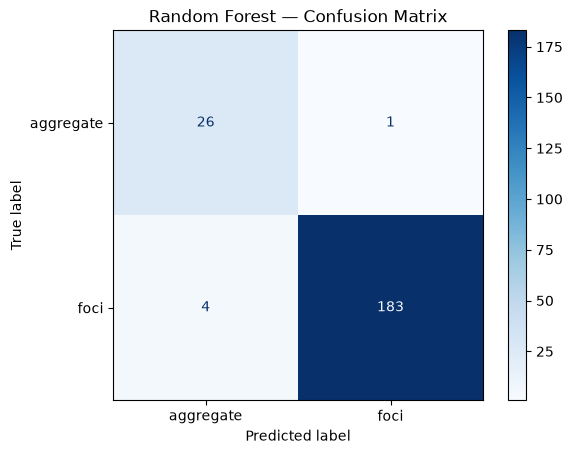

In [22]:
y_pred = rf.predict(X_test)

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)

plt.title("Random Forest — Confusion Matrix")
plt.show()

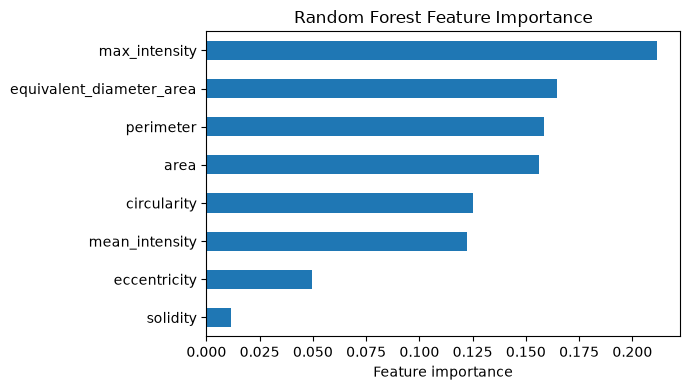

In [23]:
importance = pd.Series(
    rf.feature_importances_,
    index=features
).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))

importance.plot.barh(ax=ax)

ax.set_xlabel("Feature importance")
ax.set_title("Random Forest Feature Importance")

plt.tight_layout()
plt.show()

                    feature  importance       std
3                 perimeter   -0.001711  0.001490
0                      area   -0.001551  0.001699
7               circularity    0.000000  0.000000
2              eccentricity    0.000588  0.001108
4                  solidity    0.003369  0.001838
5            mean_intensity    0.005934  0.008224
1  equivalent_diameter_area    0.014005  0.007188
6             max_intensity    0.028404  0.011143


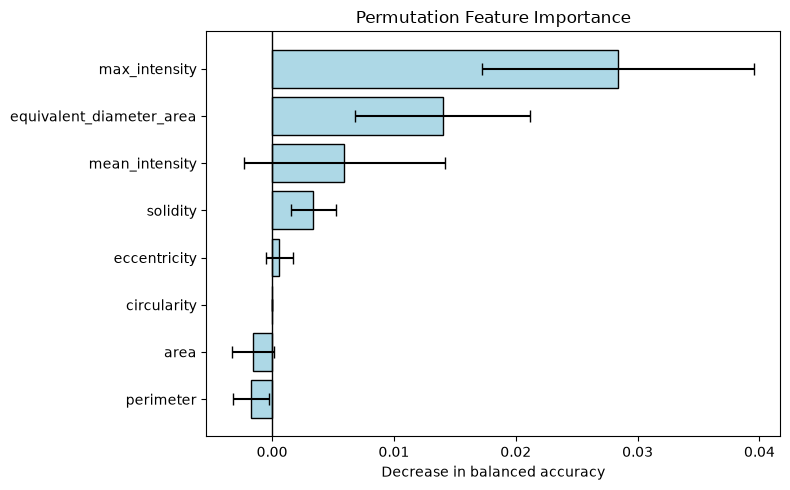

In [24]:
result = permutation_importance(
    rf,
    X_test,
    y_test,
    n_repeats=50,
    random_state=42,
    scoring="balanced_accuracy"
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": result.importances_mean,
    "std": result.importances_std
})

importance_df = importance_df.sort_values("importance")

print(importance_df)

fig, ax = plt.subplots(figsize=(8, 5))

ax.barh(
    importance_df["feature"],
    importance_df["importance"],
    xerr=importance_df["std"],
    color="lightblue",
    edgecolor="black",
    capsize=4
)

ax.axvline(0, color="black", linewidth=1)

ax.set_xlabel("Decrease in balanced accuracy")
ax.set_title("Permutation Feature Importance")

plt.tight_layout()
plt.show()

In [25]:
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score
)

for name, X, y in [
    ("Training", X_train, y_train),
    ("Test", X_test, y_test)
]:
    y_pred = rf.predict(X)

    print(f"\n{name}")
    print(
        "Balanced accuracy:",
        balanced_accuracy_score(y, y_pred)
    )
    print(
        "Aggregate F1:",
        f1_score(y, y_pred, pos_label="aggregate")
    )
    
    print(
        "Foci F1:",
        f1_score(y, y_pred, pos_label="foci")
    )



Training
Balanced accuracy: 0.9839285714285715
Aggregate F1: 0.9010989010989011
Foci F1: 0.9836660617059891

Test
Balanced accuracy: 0.9707862943157061
Aggregate F1: 0.9122807017543859
Foci F1: 0.9865229110512129


# Information about features

### Feature distribution

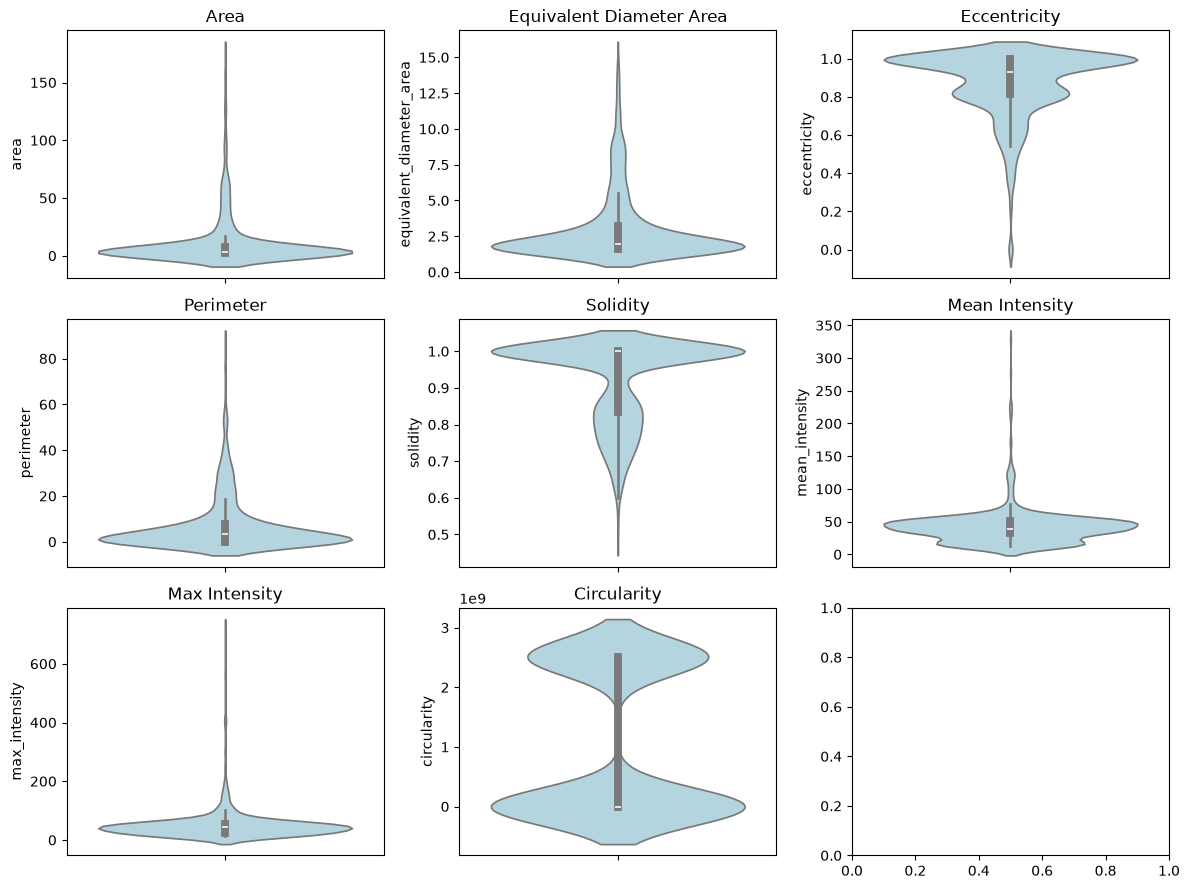

In [29]:
features = [
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
    "circularity",
]

# Clean column names
df = df.copy()
df.columns = df.columns.str.strip().str.lower()

# Convert features to numeric
df[features] = df[features].apply(
    pd.to_numeric,
    errors="coerce"
)

fig, axes = plt.subplots(3, 3, figsize=(12, 9))

for ax, feature in zip(axes.flat, features):

    sns.violinplot(
        data=df,
        y=feature,
        color="lightblue",
        inner="box",
        legend=False,
        ax=ax
    )
    
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()


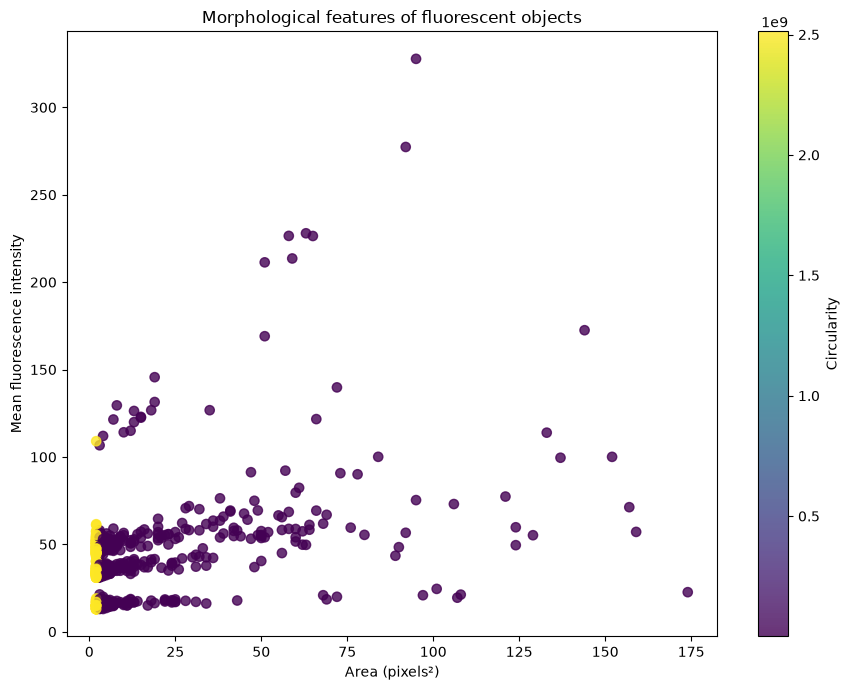

In [34]:
fig, ax = plt.subplots(figsize=(9, 7))

sc = ax.scatter(
    df["area"],
    df["mean_intensity"],
    c=df["circularity"],
    cmap="viridis",
    s=45,
    alpha=0.8
)

plt.colorbar(sc, ax=ax, label="Circularity")

ax.set_xlabel("Area (pixels²)")
ax.set_ylabel("Mean fluorescence intensity")
ax.set_title("Morphological features of fluorescent objects")

plt.tight_layout()
plt.show()

#  Run PCA

In [ ]:
# Select objects with known classes and complete features
pca_df = df.dropna(subset=features + ["class"]).copy()

# Select features and scale them 
X = pca_df[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

### Heatmap of PCA loadings

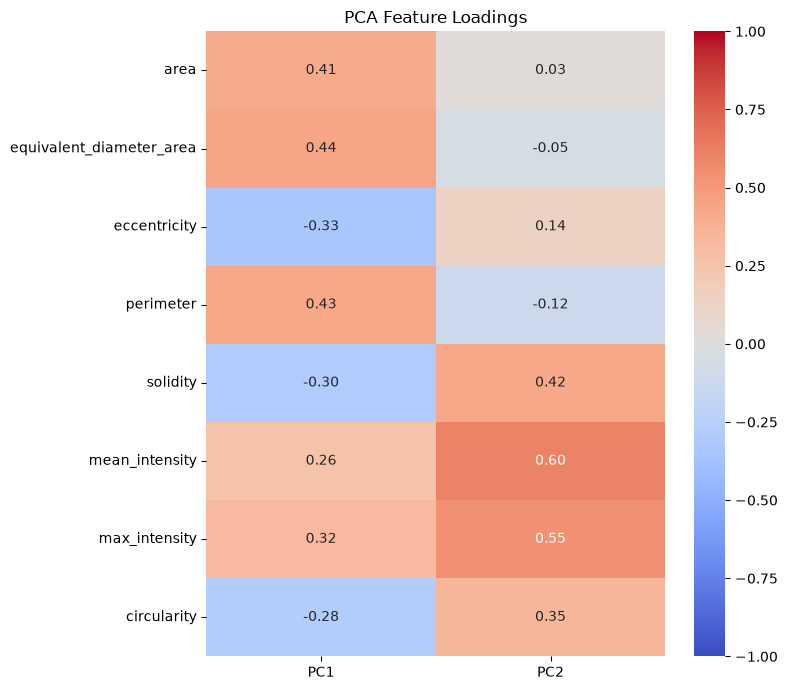

In [62]:
# PCA coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=['PC1', 'PC2']
)

#display(loadings.round(3))

# Heatmap of PCA loadings
plt.figure(figsize=(8, 7))

sns.heatmap(
    loadings[["PC1", "PC2"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

In [ ]:
# Select objects with known classes and complete features
pca_df = df.dropna(subset=features + ["class"]).copy()

# Select features and scale them 
X = pca_df[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

## Plot PCA

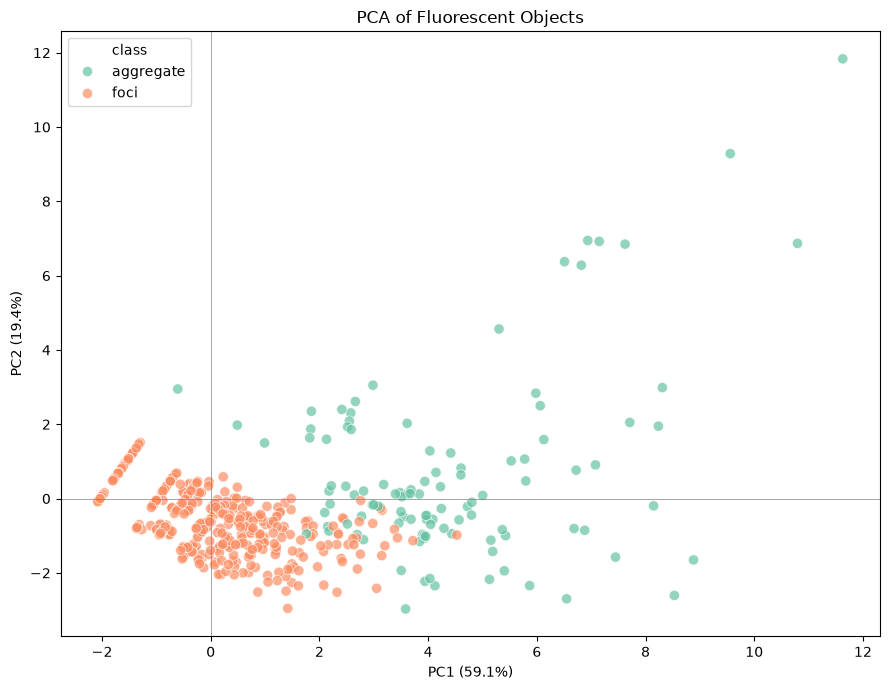

In [72]:
pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="class",
    palette="Set2",
    s=55,
    alpha=0.7
)

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("PCA of Fluorescent Objects")
plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(0, color="gray", linewidth=0.5)

plt.tight_layout()
plt.show()

### Cluster analysis

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import HDBSCAN
from sklearn.metrics import silhouette_score

# PCA coordinates
X = pca_df[["PC1", "PC2"]].to_numpy()

# HDBSCAN clustering
clusterer = HDBSCAN(
    min_cluster_size=25,
    min_samples=10
)

clusters = clusterer.fit_predict(X)

# Add clusters to DataFrame
pca_df = pca_df.copy()
pca_df["cluster"] = clusters

# Number of clusters (excluding noise = -1)
n_clusters = len(set(clusters) - {-1})

print("Number of clusters:", n_clusters)
print("Number of outliers:", np.sum(clusters == -1))

print("\nObjects per cluster:")
print(pca_df["cluster"].value_counts().sort_index())

In [ ]:
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="tab10",
    s=55,
    alpha=0.8
)

plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(0, color="gray", linewidth=0.5)

plt.title(f"HDBSCAN Clustering: {n_clusters} clusters")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_clusters_on_image(image, pca_df):

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(image, cmap="gray")

    clusters = sorted(pca_df["cluster"].dropna().unique())
    cmap = plt.get_cmap("tab20")

    for i, cluster in enumerate(clusters):

        subset = pca_df[pca_df["cluster"] == cluster]

        color = "gray" if cluster == -1 else cmap(i % 20)

        ax.scatter(
            subset["centroid-1"],  # X
            subset["centroid-0"],  # Y
            s=60,
            facecolors="none",
            edgecolors=[color],
            linewidths=1.5,
            label=f"Cluster {int(cluster)}"
        )

    ax.set_title("HDBSCAN clusters on microscopy image")
    ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    ax.axis("off")

    plt.tight_layout()
    plt.show()
    
plot_clusters_on_image(image, pca_df)

In [ ]:
import matplotlib.pyplot as plt

def plot_one_cluster(image, pca_df, cluster_id):

    # Select only objects from the requested cluster
    subset = pca_df[pca_df["cluster"] == cluster_id]

    fig, ax = plt.subplots(figsize=(10, 10))

    # Original microscopy image
    ax.imshow(image, cmap="gray")

    # Highlight selected objects
    ax.scatter(
        subset["centroid-1"],  # X
        subset["centroid-0"],  # Y
        s=60,
        facecolors="none",
        edgecolors="red",
        linewidths=1.5
    )

    ax.set_title(
        f"Cluster {cluster_id} — {len(subset)} objects"
    )

    ax.axis("off")
    plt.tight_layout()
    plt.show()

In [ ]:
plot_one_cluster(image, pca_df, cluster_id=0)

In [ ]:
import matplotlib.pyplot as plt

def plot_selected_clusters(image, pca_df, cluster_ids):

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(image, cmap="gray")

    cmap = plt.get_cmap("tab10")

    for i, cluster_id in enumerate(cluster_ids):

        subset = pca_df[pca_df["cluster"] == cluster_id]

        ax.scatter(
            subset["centroid-1"],  # X
            subset["centroid-0"],  # Y
            s=60,
            facecolors="none",
            edgecolors=[cmap(i % 10)],
            linewidths=1.5,
            label=f"Cluster {cluster_id} ({len(subset)} objects)"
        )

    ax.set_title(f"Selected clusters: {cluster_ids}")
    ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
plot_selected_clusters(
    image,
    pca_df,
    cluster_ids=[2, -1]
)

In [ ]:
results = []

for min_size in [5, 10, 15, 20, 30, 40]:
    for min_samples in [3, 5, 10, 20, 30]:

        model = HDBSCAN(
            min_cluster_size=min_size,
            min_samples=min_samples
        )

        labels = model.fit_predict(X)

        mask = labels != -1

        n_clusters = len(set(labels) - {-1})
        n_noise = np.sum(~mask)

        # Silhouette score excluding noise
        if n_clusters >= 2 and mask.sum() > n_clusters:
            score = silhouette_score(
                X[mask],
                labels[mask]
            )
        else:
            score = np.nan

        results.append({
            "min_cluster_size": min_size,
            "min_samples": min_samples,
            "n_clusters": n_clusters,
            "n_noise": n_noise,
            "noise_fraction": n_noise / len(X),
            "silhouette": score
        })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "silhouette",
        ascending=False
    )
)

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))

sns.lineplot(
    data=results_df,
    x="min_cluster_size",
    y="n_clusters",
    hue="min_samples",
    marker="o",
    palette="viridis",
    ax=ax
)

ax.set_xlabel("Minimum cluster size")
ax.set_ylabel("Number of detected clusters")
ax.set_title("HDBSCAN parameter sensitivity")

plt.tight_layout()
plt.show()

### Correlation analysis

In [ ]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    X.corr(),
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation")
plt.tight_layout()
plt.show()

# Random forest

In [ ]:
from matplotlib.patches import Rectangle

In [ ]:
df

In [ ]:
show_object(image, labels, object_id=7)

In [ ]:
df["class"] = ""

df.to_csv("foci_features_to_label.csv", index=False)

In [ ]:
df_labeled = pd.read_csv("foci_features_to_label.csv")


In [ ]:
df_labeled

In [ ]:
features = [
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "solidity",
    "perimeter",
    "mean_intensity",
    "max_intensity",
    "min_intensity",
    "circularity"
]

X = df_labeled[features]
y = df_labeled["class"]

# Train using manually labeled objects
model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X, y)

print("Random Forest trained successfully!")